In [1]:
import agama, numpy, matplotlib, matplotlib.pyplot as plt
from scipy import optimize 
from astropy import units as u 
from astropy import constants as cnst
# import hunter2024mwmodel as h2024
import barframe
plt.rcParams.update({
    "font.size": 11,
    "axes.labelsize": 11,
    "axes.titlesize": 11,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "text.usetex": True,
    "text.latex.preamble": r"\usepackage{txfonts}",
})


In [2]:
# omega= -37.5
# bar1    =   h2024.coleman2020(**h2024.coleman_components)
# bar2    =   h2024.portail_component(**h2024.portail_bar_1)
# bar3    =   h2024.portail_component(**h2024.portail_bar_2)    
# pbar1   =   agama.Potential(type='CylSpline', density=bar1,symmetry='triaxial',mmax=8,gridSizeR=40, gridSizeZ=40, Rmin=0.001, Rmax=20, Zmin=0.001, Zmax=20)
# pbar2   =   agama.Potential(type='CylSpline', density=bar2,symmetry='triaxial',mmax=8,gridSizeR=40, gridSizeZ=40, Rmin=0.001, Rmax=20, Zmin=0.001, Zmax=20)
# pbar3   =   agama.Potential(type='CylSpline', density=bar3,symmetry='triaxial',mmax=8,gridSizeR=40, gridSizeZ=40, Rmin=0.001, Rmax=20, Zmin=0.001, Zmax=20)
# pbar    =   pbar1+pbar2+pbar3

# # the rest of the potetial 
# psagA       =   agama.Potential(**h2024.supermassiveblackhole)
# pnsc        =   agama.Potential(**h2024.nsc)
# pnsd1       =   agama.Potential(**h2024.NSD1,)
# pnsd2       =   agama.Potential(**h2024.NSD2)
# pdisk1      =   agama.Potential(**h2024.DISK1)
# pdisk2      =   agama.Potential(**h2024.DISK2)
# pgdisk1     =   agama.Potential(**h2024.GDISK1)
# pgdisk2     =   agama.Potential(**h2024.GDISK2)
# phalo       =   agama.Potential(**h2024.EINASTO)
# pot_total   =   agama.Potential(pbar1,pbar2,pbar3,psagA,pnsc,pnsd1,pnsd2,pdisk1,pdisk2,pgdisk1,pgdisk2,phalo)
# pot_total_rotating = agama.Potential(potential=pot_total, rotation = [[0,0],[1,omega]])

In [3]:
def rotate(posvel, angle):
    x, y, z, vx, vy, vz = posvel.T
    sina, cosa = numpy.sin(angle), numpy.cos(angle)
    return numpy.array([x*cosa-y*sina, x*sina+y*cosa, z, vx*cosa-vy*sina, vx*sina+vy*cosa, vz]).T

NOTE. Try and put omega in the potential and integrate in the inertial frame for creating the library. 

In [4]:
# TRY A SIMPLER MODEL FIRST 
bartype = "Ferrers"
barmass = 1e10
barScaleRadius = 5.5
axisRatioY = 0.35
axisRatioZ = 0.25

type_d1 = "MiyamotoNagai"
mass_d1 = 6e10/barmass
scaleRadius_d1 = 3.5/barScaleRadius
scaleHeight_d1 = 0.28/barScaleRadius

type_d2 = "MiyamotoNagai"
mass_d2 = 1e10/barmass
scaleRadius_d2 = 2.0/barScaleRadius
scaleHeight_d2 = 0.8/barScaleRadius

type_halo = "NFW"
mass_halo = 1e12/barmass
scaleRadius_halo = 20.0/barScaleRadius

In [5]:
unitM = barmass*u.Msun
unitL = barScaleRadius*u.kpc 
oldUnitG = (u.km/u.s)**2 * (u.kpc/u.Msun)
G=cnst.G.to(oldUnitG)
unitV = (G*unitM/unitL)**(1/2)
agama.setUnits(length=unitL.value, mass=unitM.value, velocity=unitV.value)   # kpc, Msun, km/s
bar     = agama.Potential(type="Ferrers",mass=1,scaleRadius=1,axisRatioY=axisRatioY,axisRatioZ=axisRatioZ)
disk1   = agama.Potential(type=type_d1,mass=mass_d1,scaleRadius=scaleRadius_d1, scaleHeight=scaleHeight_d1)
disk2   = agama.Potential(type=type_d2,mass=mass_d2,scaleRadius=scaleRadius_d2, scaleHeight=scaleHeight_d2)
halo    = agama.Potential(type=type_halo,mass=mass_halo,scaleRadius=scaleRadius_halo, )
potential = bar + disk1 + disk2 + halo

In [6]:
unitRotation    =  unitV/unitL
omegaOld        = 37.5 * u.km / u.kpc / u.s
omegaNew        = omegaOld.to(unitRotation)
omega           = omegaNew.value
potential_rotating = agama.Potential(potential=potential, rotation = [[0,0], [1, omega]])

In [7]:
norbits     =   int(1e4)
ics,mass    =   bar.sample(norbits, potential=potential, beta=1/2,kappa=1/10)

In [8]:
xl1, EL1 = barframe.lagrange_l1_energy(potential, omega)
xvzc,yvzc = barframe.xy_plane_zero_velocity_curve(potential,omega,EL1)

[None,
 Text(0, 0.5, '$\\rho$ [Ferrers]'),
 Text(0.5, 0, 'x $[a_{\\mathrm{bar}}]$')]

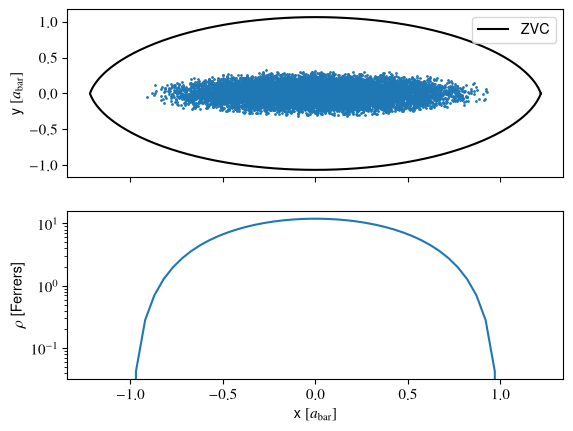

In [9]:
fig,axis=plt.subplots(2,1,sharex=True)
axis[0].scatter(ics[:,0],ics[:,1],s=1)
axis[0].plot(xvzc,yvzc,color="k",label="ZVC")
axis[0].set(ylabel=r"y $[a_{\mathrm{bar}}]$")
lgnd=axis[0].legend()
xs = numpy.linspace(-xl1,xl1)
pos = numpy.column_stack((xs,0*xs,0*xs))

axis[1].plot(numpy.linspace(-xl1,xl1), bar.density(pos));
axis[1].set(yscale="log",ylabel=r"$\rho$ [Ferrers]", xlabel=r"x $[a_{\mathrm{bar}}]$")

### Targets? 

1. First, just to the density naively, without regularisation with too few particles to see what happens 


**Questions**
- how do we get 704 bins for this binning scheme?

In [65]:
# DensityCylindricalLinear
stripsPerPane   =   2
gridr           =   agama.nonuniformGrid(11, 0.1, 1,)
target_density  =   agama.Target(type = "DensityClassicLinear",gridr = gridr, stripsPerPane = stripsPerPane, axisRatioY=axisRatioY, axisRatioZ=axisRatioZ)
times           =   50*potential.Tcirc(ics)

In [66]:
D,traj=agama.orbit(ic=ics,
                   potential=potential,
                   Omega=omega,
                   dtype=object,
                   time=times,
                   separateTime=True, 
                   targets=target_density)

10000 orbits complete (1246 orbits/s)


In [68]:
Lz = ics[:,0]*ics[:,4] - ics[:,1]*ics[:,3]
EJ = potential.potential(ics[:,:3]) + 0.5*numpy.sum(ics[:,3:]**2, axis=1) - omega*Lz
print((EJ > EL1).mean())

0.1347


In [69]:
# the bar mass
total_bar_mass = bar.totalMass()
# make each star the same mass
w = numpy.ones(norbits) * total_bar_mass / norbits
# get the discrete mass for each chunk
mass_discrete = D.T.dot(w)
mass_true = target_density(bar)

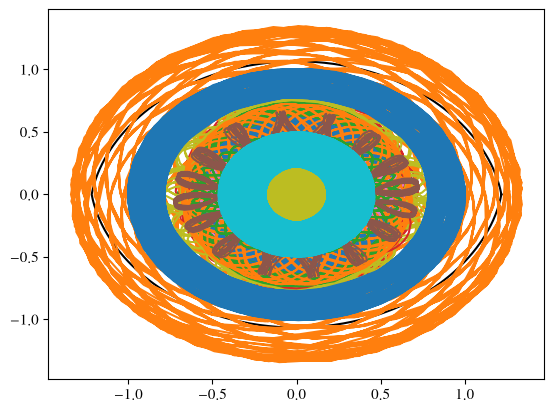

In [70]:
fig,axis=plt.subplots(1,1)
axis.plot(xvzc,yvzc,color="k",label="ZVC")
for index in range(100):
    axis.plot(traj[index](traj[index])[:,0],traj[index](traj[index])[:,1])

In [71]:
print((mass_true==0).sum(), )
print(len(mass_true))
print((D.sum(axis=0)==0).sum())

95
191
0


In [72]:
print(type(traj[index](traj[index])))
print(traj[index](traj[index]).shape)

<class 'numpy.ndarray'>
(1849, 6)


In [73]:
def r_ell(xv):
    return numpy.sqrt(xv[:,0]**2 + (xv[:,1]/axisRatioY)**2 + (xv[:,2]/axisRatioZ)**2)
i=2
t = numpy.linspace(traj[i][0], traj[i][-1], 2000)
print(r_ell(traj[i](t)).max())

2.0760519737281173


[Text(0, 0.5, 'discretized'), Text(0.5, 0, 'true mass'), None]

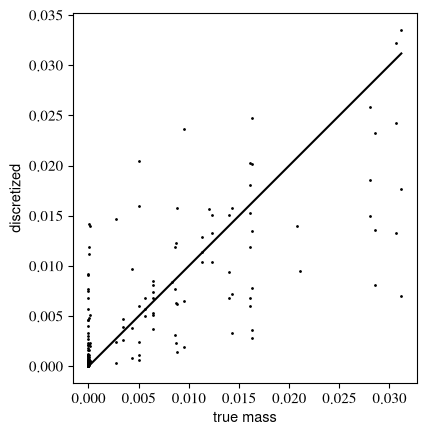

In [74]:
fig,axis = plt.subplots(1,1)
axis.scatter(mass_true,mass_discrete,s=1,color="k");
axis.plot([mass_true.min(), mass_true.max()],[mass_true.min(), mass_true.max()],zorder=10,color="k")
axis.set(ylabel="discretized", xlabel="true mass",aspect="equal")

In [75]:
data0 = numpy.ones((1, norbits))

try and make the constrain vector for the quadratic optimization 

In [76]:
constraints_density_uncertainty = 0.1 * mass_true

In [77]:
sigma   = numpy.maximum(0.1*mass_true, 0.05*mass_true.mean())
regul   = 1.0
weights = agama.solveOpt(
    matrix=[data0, D.T],
    rhs=[[total_bar_mass], mass_true],
    rpenq=[[numpy.inf], 2*sigma**-2],
    xpenq=2*numpy.ones(norbits)*norbits/total_bar_mass**2*regul)

Using a custom optimized KKT solver
numVariables=10191, numConstraints=192, numConsIneq=10000
Benchmarking BLAS backends for matrix size=(192,10191): cvxopt=0.001 s, numpy=0.002 s, scipy=0.004 s => choosing cvxopt
     pcost       dcost       gap    pres   dres
 0:  8.0646e+01  7.9641e+01  1e+04  1e+02  1e+02
 1:  8.0646e+01  7.9654e+01  2e+02  2e+00  2e+00
 2:  8.0646e+01  8.0086e+01  7e+01  7e-01  7e-01
 3:  8.2812e+01  8.0776e+01  7e+01  6e-01  6e-01
 4:  8.3411e+01  8.4402e+01  7e+01  4e-01  4e-01
 5:  8.4216e+01  8.9244e+01  6e+01  3e-01  3e-01
 6:  8.5774e+01  9.5949e+01  5e+01  2e-01  2e-01
 7:  8.7750e+01  1.0355e+02  5e+01  2e-01  2e-01
 8:  9.2781e+01  1.1850e+02  5e+01  1e-01  1e-01
 9:  9.8014e+01  1.3663e+02  5e+01  1e-01  1e-01
10:  1.0449e+02  1.5826e+02  5e+01  9e-02  9e-02
11:  1.1146e+02  1.8020e+02  5e+01  8e-02  8e-02
12:  1.1916e+02  2.0356e+02  6e+01  7e-02  7e-02
13:  1.3029e+02  2.3310e+02  7e+01  6e-02  6e-02
14:  1.4173e+02  2.6140e+02  7e+01  5e-02  5e-02
15:

total mass: 1.00000000096284 target: 1.0000000000000064
chi2/ncells: 6.171828637307169
cells off by > 1 sigma: 62 of 191


[Text(0.5, 0, '(model - true)/$\\sigma$')]

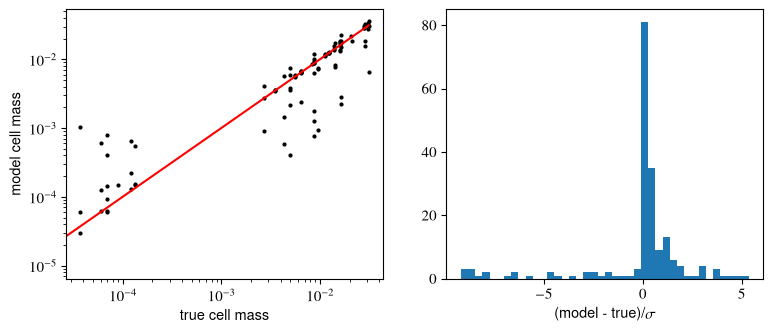

In [78]:
mass_model = D.T.dot(weights)
rel = (mass_model - mass_true) / sigma          # in units of the tolerance
print("total mass:", weights.sum(), "target:", total_bar_mass)
print("chi2/ncells:", numpy.mean(rel**2))
print("cells off by > 1 sigma:", (abs(rel) > 1).sum(), "of", len(rel))

fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
ax[0].scatter(mass_true, mass_model, s=4, c="k")
ax[0].plot([mass_true.min(), mass_true.max()], [mass_true.min(), mass_true.max()], "r")
ax[0].set(xscale="log", yscale="log", xlabel="true cell mass", ylabel="model cell mass")
ax[1].hist(rel, bins=40); ax[1].set(xlabel=r"(model - true)/$\sigma$")

In [79]:

def analyze_weights(weights):
    n = len(weights)
    nw = weights * n / weights.sum()
    print("max weight (closer to 1 = better): %.3g" % nw.max())
    print("mean square weight (closer to 1 = better): %.3g" % numpy.mean(nw**2))
    print("orbits carrying 90%% of mass: %i / %i" %
          (numpy.searchsorted(numpy.cumsum(numpy.sort(weights)[::-1]), 0.9*weights.sum()), n))
    print("orbits with weight < 1e-3 of mean: %i" % (nw < 1e-3).sum())
analyze_weights(weights)

max weight (closer to 1 = better): 215
mean square weight (closer to 1 = better): 66
orbits carrying 90% of mass: 204 / 10000
orbits with weight < 1e-3 of mean: 9666


In [ ]:
frac_inside = D.sum(axis=1)
nw = weights * norbits / weights.sum()
fig, ax = plt.subplots(1, 3, figsize=(12, 3.5))
ax[0].scatter(frac_inside, nw, s=2); ax[0].set(xlabel="fraction of time inside grid", ylabel="norm. weight", yscale="log")
ax[1].scatter(EJ, nw, s=2); ax[1].axvline(EL1, c="r"); ax[1].set(xlabel="Jacobi energy", yscale="log")
r0 = numpy.sqrt(ics[:,0]**2 + (ics[:,1]/axisRatioY)**2 + (ics[:,2]/axisRatioZ)**2)
ax[2].scatter(r0, nw, s=2); ax[2].set(xlabel="initial elliptical radius", yscale="log")

[Text(0.5, 0, 'initial elliptical radius'), None]